In [1]:
import sys            
import os

from matplotlib.backends.backend_qtagg    import FigureCanvasQTAgg
from datetime                             import datetime

from PySide6.QtGui                        import QPainterPath, QRegion
from PySide6.QtCore                       import QTimer, Qt, Slot
from PySide6.QtWidgets                    import (QApplication,QMainWindow,QLabel, QScrollArea,QFormLayout,QSizePolicy,
                                                   QPushButton,QLineEdit,QMessageBox,QProgressBar,QFrame,
                                                   QWidget,QDialog,QVBoxLayout,QHBoxLayout,QStyle,QComboBox,
                                                   QStackedWidget,QGroupBox,QTextEdit,QGridLayout)

from gui_design.system_monitor_widget     import SystemMonitorWidget
from gui_design.experiment_profile_dialog import ExperimentProfileDialog
from gui_design.stylish_widgets           import MetricCard, LogViewer, StatusBadge, LogViewer

from doe_sampling.doe_sampler             import DoESampler
from doe_sampling.doe_creator             import ExperimentCreator

from exp_generation.profile_gen           import DefineProcessParameter
from exp_generation.profile_gen           import ProfileCreator
from exp_generation.profile_gen           import ExperimentProfileParameters
from exp_generation.profile_gen           import ExperimentProfileStorage
from exp_generation.profile_gen           import ExpComponentGen
from exp_generation.profile_gen           import ProfileGenerator
from exp_generation.pump_calibration      import PumpRateConverter

from app_control.pure_functions           import counter
from app_control.Controller               import Controller, Stage
from app_control.DataPlotter              import DataPlotter


In [2]:
gui qt

AS_add_time
T_final
AS_add_time
T_final
AS_add_time
T_final
AS_add_time
T_final


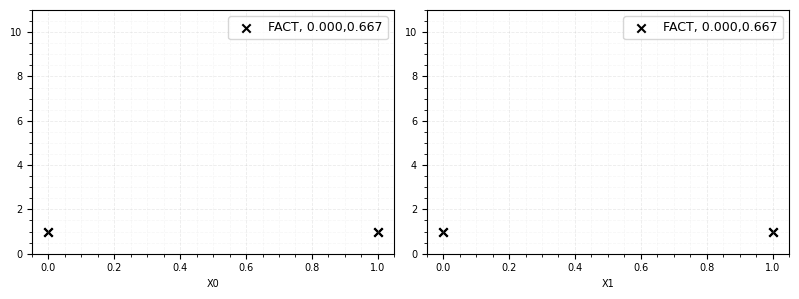

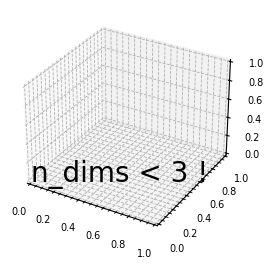

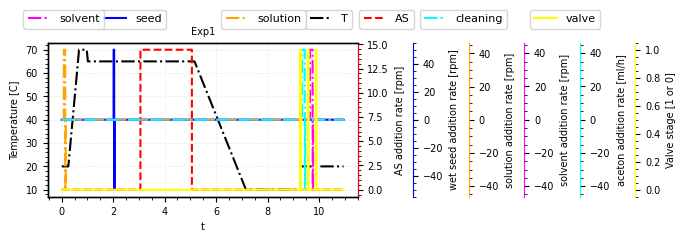

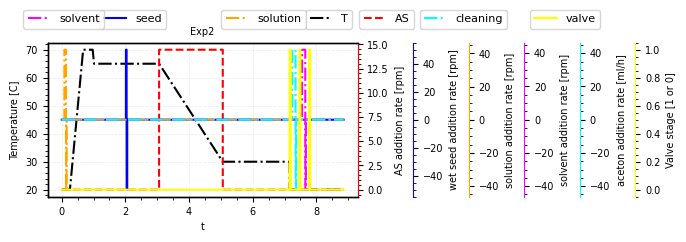

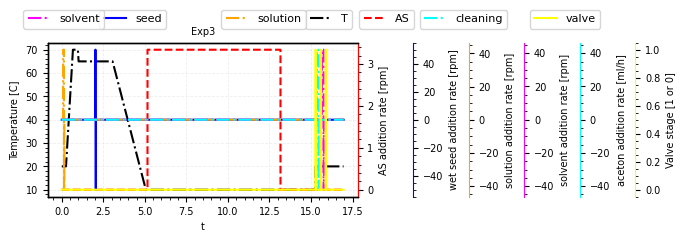

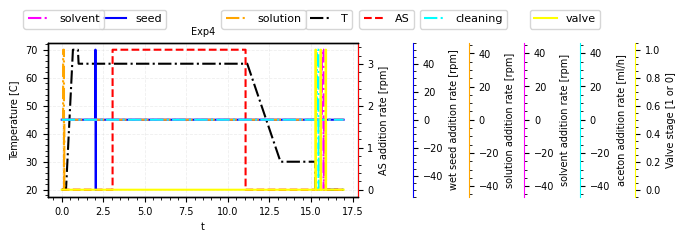

In [8]:
class MainWindow(QMainWindow):

  def __init__(self):
        super().__init__()
        self.setWindowFlags( Qt.WindowType.Window |  Qt.WindowType.FramelessWindowHint |  Qt.WindowType.WindowSystemMenuHint)
        self.setAttribute(Qt.WidgetAttribute.WA_TranslucentBackground, True)
        
        self.SPACING_1 = 8
        self.SPACING_2 = 16
        self.SPACING_3 = 24
        self.SPACING_4 = 32
        
        self.resize(1100, 500)

        central_widget = QWidget()
        central_widget.setObjectName("centralContainer") 
        self.setCentralWidget(central_widget)

        # 1. Root layout is a VERTICAL layout to stack the Header on top
        root_layout = QVBoxLayout(central_widget)
        root_layout.setContentsMargins(0, 0, 0, 0)
        root_layout.setSpacing(0)

        # ----------------------------------------------------------------- #
        # TOP HEADER BAR                                                    #
        # ----------------------------------------------------------------- #
        header_widget = QWidget()
        header_widget.setObjectName("topHeader")
        header_widget.setFixedHeight(50)
        header_layout = QHBoxLayout(header_widget)
        header_layout.setContentsMargins(15, 0, 10, 0)
        header_layout.setSpacing(8)
        
        # App Logo & Title
        logo_label = QLabel("⚛  ECC 1.0 - Experiment Control Center")
        logo_label.setStyleSheet("font-weight: bold; font-size: 15px; color: white; background: transparent;")
        
        # System Ready Status Pill
        status_pill = QLabel("● System Ready")
        status_pill.setObjectName("statusPill")
        
        # Window Control Buttons (Minimize, Close)
        self.btn_minimize = QPushButton("—")
        self.btn_minimize.setObjectName("windowControlBtn")
        self.btn_minimize.setFixedSize(30, 30)
        self.btn_minimize.clicked.connect(self.showMinimized)

        self.btn_close = QPushButton("✕")
        self.btn_close.setObjectName("windowCloseBtn")
        self.btn_close.setFixedSize(30, 30)
        self.btn_close.clicked.connect(self.close)

        header_layout.addWidget(logo_label)
        header_layout.addStretch()
        header_layout.addWidget(status_pill)
        header_layout.addSpacing(15)
        header_layout.addWidget(self.btn_minimize)
        header_layout.addWidget(self.btn_close)

        root_layout.addWidget(header_widget)

        # ----------------------------------------------------------------- #
        # BODY CONTAINER (Holds Sidebar on left, Content Stack on right)      #
        # ----------------------------------------------------------------- #
        body_widget = QWidget()
        body_widget.setObjectName("bodyContainer")
        body_layout = QHBoxLayout(body_widget)
        body_layout.setContentsMargins(0, 0, 0, 0)
        body_layout.setSpacing(0)

        # ----------------------------------------------------------------- #
        # 1. LEFT SIDEBAR NAVIGATION PANEL                                  #
        # ----------------------------------------------------------------- #
        sidebar_widget = QWidget()
        sidebar_widget.setObjectName("sidebar")
        sidebar_widget.setFixedWidth(220)
        sidebar_layout = QVBoxLayout(sidebar_widget)
        sidebar_layout.setContentsMargins(15, 20, 15, 20)
        sidebar_layout.setSpacing(self.SPACING_2)

        # Create navigation buttons
        self.btn_dashboard = QPushButton("🏠  Dashboard")
        self.btn_experiment = QPushButton("🧪  Experiment")
        self.btn_plots = QPushButton("📊  Data & Plots")
        self.btn_brain = QPushButton("🧠  Brain")
        self.btn_settings = QPushButton("⚙️  Settings")

        nav_buttons = [self.btn_dashboard,self.btn_experiment,self.btn_plots,self.btn_brain,self.btn_settings]

        for btn in nav_buttons:
            btn.setCheckable(True)
            sidebar_layout.addWidget(btn)

        sidebar_layout.addSpacing(15)

        quick_label = QLabel("Quick Actions")
        quick_label.setStyleSheet("color: #64748b; font-size: 11px; font-weight: bold; background: transparent;")
        sidebar_layout.addWidget(quick_label)

        self.quick_start_btn = QPushButton("▶ Start")
        self.quick_start_btn.setObjectName("start_button")
        self.quick_stop_btn = QPushButton("⏹ Stop")
        self.quick_stop_btn.setObjectName("stop_button")
        self.quick_reset_btn = QPushButton("🔄 Reset")
        self.quick_reset_btn.setObjectName("reset_button")
        self.quick_quit_btn = QPushButton("🔐 Quit")
        self.quick_quit_btn.setObjectName("quit_button")

        quick_actions = [ self.quick_start_btn, self.quick_stop_btn, self.quick_reset_btn, self.quick_quit_btn]
      
        for qbtn in quick_actions:
            sidebar_layout.addWidget(qbtn)

        self.quick_start_btn.clicked.connect(self.start_command)
        self.quick_stop_btn.clicked.connect(self.stop_command)
        self.quick_reset_btn.clicked.connect(self.reset_command)
        self.quick_quit_btn.clicked.connect(self.close)

        sidebar_layout.addStretch()

        # ----------------------------------------------------------------- #
        # 2. RIGHT SIDE: STACKED WIDGET (CONTENT VIEWS)                     #
        # ----------------------------------------------------------------- #
        self.stack = QStackedWidget()

        self.dashboard_page = QWidget()
        self.setup_dashboard_view()

        self.experiment_page = QWidget()
        self.setup_experiment_view()

        self.plots_page = QWidget()
        self.setup_plots_view()

        self.brain_page = QWidget()
        self.setup_brain_view()

        self.settings_page = QWidget()
        self.setup_settings_view()

        self.stack.addWidget(self.dashboard_page)
        self.stack.addWidget(self.experiment_page)
        self.stack.addWidget(self.plots_page)
        self.stack.addWidget(self.brain_page)
        self.stack.addWidget(self.settings_page)

        self.btn_dashboard.clicked.connect(lambda: self.switch_page(0))
        self.btn_experiment.clicked.connect(lambda: self.switch_page(1))
        self.btn_plots.clicked.connect(lambda: self.switch_page(2))
        self.btn_brain.clicked.connect(lambda: self.switch_page(3))
        self.btn_settings.clicked.connect(lambda: self.switch_page(4))

        self.btn_dashboard.setChecked(True)
        self.stack.setCurrentIndex(0)

        body_layout.addWidget(sidebar_widget)
        body_layout.addWidget(self.stack)

        # Add the body container right below the header in the root layout
        root_layout.addWidget(body_widget)

        # ----------------------------------------------------------------- #
        # CONSTANTS, MODULES, AND INTERNAL VARIABLES                        #
        # ----------------------------------------------------------------- #

        as_pump_cal_location   = r"FILES\pump_calibration\expttsd1_AS.csv"
        solu_pump_cal_location = r"FILES\pump_calibration\expttsd1_SOLU.csv"
        solv_pump_cal_location = r"FILES\pump_calibration\expttsd1_SOLV.csv"
        
        as_rate_converter           = PumpRateConverter(as_pump_cal_location,  'File  W: AS ',      'File R: Mass ')  
        solution_rate_converter     = PumpRateConverter(solu_pump_cal_location,'P01:Value (Setpt)', 'File R: Mass ')  
        solvent_rate_converter      = PumpRateConverter(solv_pump_cal_location,'P01:Value (Setpt)', 'File R: Mass ')  
        cleaning_sol_rate_converter = PumpRateConverter(solv_pump_cal_location,'P01:Value (Setpt)', 'File R: Mass ') 
        
        self.doe_sampler   = DoESampler()                                             # ...generating the settings for Experiments
        self.component_gen = ExpComponentGen() # ...functions for experiment section generation
        self.exp_par       = ExperimentProfileParameters()                            # ...storing the parameters for DoE profile generation
        self.profiles      = ProfileGenerator(self.exp_par, self.component_gen)       
        self.exp_storage   = ExperimentProfileStorage(as_rate_converter, solution_rate_converter, solvent_rate_converter,  cleaning_sol_rate_converter) 
        
        self.omni_filename  = "expttsd"
        self.MODEL_filename = "MODEL"

        self.variables_set               = False
        self.process_stop                = False
        self.CONTROLLER                  = None
        self.DATAPROCESSOR               = None
        self.create_experiments          = None
      
        self.initial_exp_count           = 0
        self.conducted_experiments_count = 0
        self.previous_exp_count          = 0
        self.MODEL_run_count             = 0
        self.omni_run_count              = 0
      
        self.omni_folder                 = ""
        self.model_folder                = ""
      
        self.timer                       = QTimer(self)
        
        self.create_style()

        self.timer.timeout.connect(self.monitoring_loop)
      
        self.monitor_mode = None
        self.monitor_path = None
        self.monitor_num  = None
        self.log_message("🌟 App opened up successfully.", "INFO")
        

  def switch_page(self, index):
    """Switches the active page in the stack and manages button states."""
    self.stack.setCurrentIndex(index)
    buttons = [self.btn_dashboard,self.btn_experiment,self.btn_plots,self.btn_brain,self.btn_settings]
    
    for i, btn in enumerate(buttons):
      if i < self.stack.count():
        btn.setChecked(i == index)

  # --- Page layout builders ---
  def setup_dashboard_view(self):
      
    # Wrap everything in a scroll area to maintain responsiveness
    scroll_area = QScrollArea(self.dashboard_page)
    scroll_area.setWidgetResizable(True)
    scroll_area.setStyleSheet("QScrollArea { border: none; background-color: transparent; }")

    scroll_content = QWidget()
    scroll_content.setObjectName("dashboard_content")
    # Use a QGridLayout for the main content area to support columns & rows
    main_grid = QGridLayout(scroll_content)
    main_grid.setContentsMargins(20, 20, 20, 20)
    main_grid.setSpacing(15)

    # ===================================================== #
    # 2. EXPERIMENT CONTROLS BOX (Middle-Left)            #
    # ===================================================== #
    control_box = QGroupBox("🧪 Experiment Controls")
    control_layout = QGridLayout()
    
    # Tighten inner margins and spacing to make it shorter
    control_layout.setContentsMargins(10, 10, 10, 10)
    control_layout.setSpacing(self.SPACING_1)

    self.start_button = QPushButton("Start Experiment")
    self.start_button.setObjectName("start_button")
    self.stop_button = QPushButton("Stop Experiment")
    self.stop_button.setObjectName("stop_button")
    self.reset_button = QPushButton("♻️ Reset System")
    self.reset_button.setObjectName("reset_button")
    self.plot_button = QPushButton("📈 Plot Data")
    self.plot_button.setObjectName("plot_button")

    self.start_button.clicked.connect(self.start_command)
    self.stop_button.clicked.connect(self.stop_command)
    self.reset_button.clicked.connect(self.reset_command)
    self.plot_button.clicked.connect(self.plot_expts)

    self.start_button.setIcon(self.style().standardIcon(QStyle.StandardPixmap.SP_MediaPlay))
    self.stop_button.setIcon(self.style().standardIcon(QStyle.StandardPixmap.SP_MediaStop))

    # Place in a compact 2x2 grid configuration
    control_layout.addWidget(self.start_button, 0, 0)
    control_layout.addWidget(self.stop_button, 0, 1)
    control_layout.addWidget(self.reset_button, 1, 0)
    control_layout.addWidget(self.plot_button, 1, 1)
    
    control_box.setLayout(control_layout)

    # ===================================================== #
    # 3. Progress track STATUS BOX (Top-Center)           #
    # ===================================================== #
    #exp_status_box = QGroupBox("📈 Progress Track")
    #exp_status_box.setObjectName("exp_status_box")
    exp_status_layout = QGridLayout()
    self.exp_status_box = QGroupBox("📈 Progress Track")
    self.exp_status_box.setObjectName("exp_status_box")  
    exp_status_layout.setContentsMargins(5, 5, 5, 5)
    exp_status_layout.setSpacing(self.SPACING_2)

    self.omni_label = QLabel("Omni")
    self.MODEL_label = QLabel("MODEL")
    self.expts_label = QLabel("Experiments")
    
    self.omni_count_label = QLabel( "0 OMNI  runs")
    self.model_count_label = QLabel("0 MODEL runs")
    self.expts_count_label = QLabel("0 EXPTS runs")
    
    self.dashboard_omni = StatusBadge("Inactive")
    self.dashboard_model = StatusBadge("Inactive")
    self.dashboard_runs = QLabel("Runs: 0 / 0")
    self.dashboard_current = QLabel("Status: Not running")
    self.variables_label = QLabel("")

    exp_status_layout.addWidget(self.omni_label, 0, 0)
    exp_status_layout.addWidget(self.MODEL_label, 0, 1)
    exp_status_layout.addWidget(self.expts_label, 0, 2)
    exp_status_layout.addWidget(self.omni_count_label, 1, 0)
    exp_status_layout.addWidget(self.model_count_label, 1, 1)
    exp_status_layout.addWidget(self.expts_count_label, 1, 2)
    exp_status_layout.addWidget(self.dashboard_omni, 2, 0)
    exp_status_layout.addWidget(self.dashboard_model, 2, 1)
    exp_status_layout.addWidget(self.dashboard_current, 3, 0, 1, 2)
    
    self.exp_status_box.setLayout(exp_status_layout)

    # ===================================================== #
    # 4. SYSTEM HEALTH / STATUS BOX (Top-Right)             #
    # ===================================================== #
    system_box = QGroupBox("💻 System Status")
    system_layout = QVBoxLayout()
    self.system_monitor = SystemMonitorWidget()
    #self.system_monitor.worker.update.connect(self.update_system_cards)
    self.system_monitor.setMaximumHeight(100)
    system_layout.addWidget(self.system_monitor)
    system_box.setLayout(system_layout)

    # ===================================================== #
    # 5. LIVE LOG WINDOW (Middle-Right / Bottom)            #
    # ===================================================== #
    log_box = QGroupBox("📜 Status Messages")
    self.dashboard_log = LogViewer()
    log_layout = QVBoxLayout()
    log_layout.addWidget(self.dashboard_log)
    log_box.setLayout(log_layout)

    # ===================================================== #
    # 6. CONNECTED DEVICES BOX (Bottom-Left)                #
    # ===================================================== #
    devices_box = QGroupBox("🔌 Connected Devices")
    devices_layout = QVBoxLayout()
    devices_layout.setContentsMargins(10, 10, 10, 10)
    devices_layout.setSpacing(self.SPACING_2)

    # Example labels for devices (you can connect these to real status logic later)
    self.device_omni_label = QLabel("❌ OMNIBUS Controller: Inactive")
    self.device_model_label = QLabel("❌ MODEL Worker: Not Ready")
    
    devices_layout.addWidget(self.device_omni_label)
    devices_layout.addWidget(self.device_model_label)
    devices_box.setLayout(devices_layout)

    # ===================================================== #
    # GRID PLACEMENT (Assembling the Multi-Column Layout) #
    # ===================================================== #
    #main_grid.addWidget(config_box, 0, 0)
    main_grid.addWidget(self.exp_status_box, 0, 1)
    main_grid.addWidget(system_box, 0, 0)

    # Row 1: Experiment Controls (col 0), Status Messages / Logs (col 1 & 2)
    main_grid.addWidget(control_box, 1, 0)
    main_grid.addWidget(log_box, 2, 0)

    # Row 2: Connected Devices (col 0 underneath controls)
    main_grid.addWidget(devices_box, 1, 1, 1, 2)

    scroll_area.setWidget(scroll_content)
    page_layout = QVBoxLayout(self.dashboard_page)
    page_layout.setContentsMargins(0, 0, 0, 0)
    page_layout.addWidget(scroll_area)   

  def setup_experiment_view(self):
    layout = QVBoxLayout(self.experiment_page)
    layout.addWidget(QLabel("<h1>Live experiment</h1><p>Experimental info plotted here.</p>"))

  def setup_plots_view(self):
    """Set up Data & Plots page with a scrollable Matplotlib container."""

    layout = QVBoxLayout(self.plots_page)
    layout.setContentsMargins(20, 20, 20, 20)
    layout.setSpacing(10)

    # Title
    title_label = QLabel("Data & Plots View")
    title_label.setStyleSheet(
        "font-size: 18px; "
        "font-weight: bold; "
        "color: #f8fafc;"
    )
    layout.addWidget(title_label)

    # ---------------------------------------------------------
    # Scroll area
    # ---------------------------------------------------------
    self.plot_scroll_area = QScrollArea()
    self.plot_scroll_area.setWidgetResizable(True)
    self.plot_scroll_area.setFrameShape(QFrame.NoFrame)

    # Optional: allow both horizontal and vertical scrolling
    self.plot_scroll_area.setHorizontalScrollBarPolicy(
        Qt.ScrollBarAsNeeded
    )
    self.plot_scroll_area.setVerticalScrollBarPolicy(
        Qt.ScrollBarAsNeeded
    )

    # ---------------------------------------------------------
    # Widget inside the scroll area
    # ---------------------------------------------------------
    self.plot_container = QWidget()

    self.plot_container_layout = QVBoxLayout(
        self.plot_container
    )

    self.plot_container_layout.setContentsMargins(
        5, 5, 5, 5
    )
    self.plot_container_layout.setSpacing(10)

    # Placeholder
    self.plot_placeholder_label = QLabel(
        "No experiment data plotted yet. "
        "Click 'Plot data' to load."
    )

    self.plot_placeholder_label.setStyleSheet(
        "color: #64748b; "
        "font-size: 13px;"
    )

    self.plot_container_layout.addWidget(
        self.plot_placeholder_label
    )

    # Important: allow contents to expand
    self.plot_container_layout.addStretch()

    # Put container inside scroll area
    self.plot_scroll_area.setWidget(
        self.plot_container
    )

    # Add scroll area to page
    layout.addWidget(
        self.plot_scroll_area,
        1
    )
    
  def setup_brain_view(self):
    layout = QVBoxLayout(self.brain_page)
    layout.addWidget(QLabel("<h1>brain</h1><p>Log info plotted here.</p>"))

  def setup_settings_view(self):
    # ===================================================== #
    # 1. EXPERIMENT CONFIGURATION BOX (Top)                 #
    # ===================================================== #
    config_box = QGroupBox("🌎 Environmental variables' settings")
    config_layout = QGridLayout()

    self.status_label = QLabel("")
    #self.status_label.setVisible(False)
    self.error_label = QLabel("")
    self.error_label.setStyleSheet("color: #ef4464;")
    #self.error_label.setVisible(False)
    self.exp_path_input = QLineEdit()
    self.exp_path_input.setPlaceholderText(r"C:\Desktop\Current_Experiment")
    self.MODEL_path_input = QLineEdit()
    self.MODEL_path_input.setPlaceholderText(r"C:\Desktop\Model_Outputs")
    self.exp_number_input = QLineEdit()
    self.exp_number_input.setPlaceholderText("5")

    self.define_button = QPushButton("Define Variables")
    self.define_button.setObjectName("define_button")
    self.define_button.clicked.connect(self.define_command)

    config_layout.addWidget(self.status_label, 0, 0, 1, 2)
    config_layout.addWidget(self.error_label, 1, 0, 1, 2)
    config_layout.addWidget(QLabel("Experiment Path"), 2, 0)
    config_layout.addWidget(self.exp_path_input, 2, 1)
    config_layout.addWidget(QLabel("MODEL Path"), 3, 0)
    config_layout.addWidget(self.MODEL_path_input, 3, 1)
    config_layout.addWidget(QLabel("Experiment Number"), 4, 0)
    config_layout.addWidget(self.exp_number_input, 4, 1)
    config_layout.addWidget(self.define_button, 5, 0, 1, 2)
    
    config_box.setLayout(config_layout)

    # ===================================================== #
    # 2. EXPERIMENT SETTINGS BOX (Top-Left)                 #
    # ===================================================== #
    exp_group = QGroupBox("⚙ Initial DoE Generation")
    form = QFormLayout()

    self.profile_button = QPushButton("Edit Experiment Profile")
    self.generate_button = QPushButton("Generate experiments")
    self.generate_button.setObjectName("generate_button")  
    
      
    self.generate_button.clicked.connect(self.define_doe)    
    self.profile_button.clicked.connect(self.open_profile_dialog)
    self.doe_type_combo = QComboBox()
    self.doe_type_combo.addItems(['Greedy minimizataion upon sobol sampling','Latin Hypercube Sampling',
                                  'Latin Hypercube Sampling + Lloyd-Max optimization','Random sampling',
                                  'Sobol sampling','Factorial DoE generation' ])
      
    form.addRow("Profile", self.profile_button)
    form.addRow("DoE type", self.doe_type_combo)
    form.addRow(self.generate_button)

    exp_group.setLayout(form)

    # ===================================================== #
    # 3. DoE INFORMATION                                    #
    # ===================================================== #
    doe_info_group = QGroupBox("DoE Information")
    doe_info_layout = QFormLayout()
    
    self.changed_dimensions_count_label = QLabel("")
    self.changed_dimensions_label = QLabel("")
    self.experiment_count_label = QLabel("")
    
    self.changed_dimensions_label.setWordWrap(True)
    
    doe_info_layout.addRow("Changed dimensions: ",self.changed_dimensions_count_label)
    doe_info_layout.addRow("Dimensions: ", self.changed_dimensions_label)
    doe_info_layout.addRow("Experiments: ", self.experiment_count_label)
    doe_info_group.setLayout(doe_info_layout)

    # ==================== #
    # Construct page
    # ==================== #
    layout = QVBoxLayout(self.settings_page)
    layout.addWidget(config_box)
    layout.addWidget(exp_group)
    layout.addWidget(doe_info_group)
    layout.addStretch()

  # ====================================================== #
  # STYLE                                                  #
  # ====================================================== #
                   
  def create_style(self):
        self.setStyleSheet("""
        QGroupBox QLabel {
            background: transparent;
            border: none;
        }

        QLabel#dashboard_current {
            background: transparent;
        }
        
        QWidget#metricCard {
            background: #111d31;     
            border: 1px solid #1e293b;  
            border-radius: 12px;
        }

        QWidget {
            background: #07111f;
            color: #e5e7eb;
            font-family: "Segoe UI";
            font-size: 13px;
        }

        QGroupBox {
            font-size: 13px;
            font-weight: 800;
            background: #111d31;
            border: 1px solid #16263d;
            border-radius: 12px;
            margin-top: 16px;
            padding: 16px;
        }

        QGroupBox#exp_status_box {
            background: #111d31;
            border: 1px solid #16263d;
            border-radius: 12px;
            margin-top: 16px;
            padding: 16px;
        }
        
        QGroupBox::title {
            subcontrol-origin: margin;
            subcontrol-position: top left;
            left: 26px;
            top: -2px;
            padding: 0px 6px;
            color: white;
            font-size: 16px;
            font-weight: 700;
        }

        QPushButton {
            background: transparent;
            color: #d6dde8;
            border: 1px solid #16263d;
            border-radius: 8px;
            padding: 11px 15px;
            text-align: left;
            font-weight: 600;
        }

        QPushButton#generate_button {
            background: #3b82f6;
            border: 1px solid #60a5fa;
            color: white;
            text-align: center;
            font-weight: 700;
            padding: 11px;
        }


        QPushButton#generate_button:hover {
            background: #2563eb;
        }
        
        QPushButton#generate_button:pressed {
            background: #10203a;
        }
        
        QPushButton#generate_button:checked {
            background: #2563eb;
            border: 1px solid #3b82f6;
            color: white;
        }
        
        QPushButton:hover {
            background: #162846;
            border: 1px solid #2f5fa7;
            color: white;
        }
        
        QPushButton:pressed {
            background: #10203a;
        }
        
        QPushButton:checked {
            background: #2563eb;
            border: 1px solid #3b82f6;
            color: white;
        }

        QPushButton#start_button {
            background: #22c55e;
            border: 1px solid #37d774;
            color: white;
            text-align: center;
            font-size: 12px;
            font-weight: 700;
            padding: 12px;
        }
        
        QPushButton#start_button:hover {
            background: #16a34a;
        }
        
        QPushButton#stop_button {
            background: #ef4444;
            border: 1px solid #f87171;
            color: white;
            text-align: center;
            font-size: 12px;
            font-weight: 700;
            padding: 12px;
        }
        
        QPushButton#stop_button:hover {
            background: #dc2626;
        }
        
        QPushButton#define_button {
            background: #3b82f6;
            border: 1px solid #60a5fa;
            color: white;
            text-align: center;
            font-weight: 700;
            padding: 11px;
        }
        
        QPushButton#define_button:hover {
            background: #2563eb;
        }

        QPushButton#define_button:pressed {
            background: #10203a;
        }

        QLineEdit {
            background: #0b1728;
            border: 1px solid #24364d;
            border-radius: 8px;
            padding: 8px 10px;
            color: white;
        }
        
        QLineEdit:focus {
            border: 1px solid #3b82f6;
        }

        QTextEdit {
            background: #081321;
            border: 1px solid #16263d;
            border-radius: 10px;
            padding: 8px;
            color: #dbe5ef;
            selection-background-color: #2563eb;
        }

        QCheckBox {
            spacing: 8px;
            color: #e2e8f0;
            font-weight: 500;
        }
        
        QCheckBox::indicator {
            width: 18px;
            height: 18px;
            border-radius: 4px;
            border: 2px solid #5b6c84;
            background: #111827;
        }
        
        QCheckBox::indicator:hover {
            border: 2px solid #60a5fa;
        }
        
        QCheckBox::indicator:checked {
            background: #2563eb;
            border: 2px solid #3b82f6;
        }

        QScrollBar:vertical {
            background: transparent;
            width: 10px;
            margin: 0px;
        }
        
        QScrollBar::handle:vertical {
            background: #2d415d;
            border-radius: 5px;
            min-height: 30px;
        }
        
        QScrollBar::handle:vertical:hover {
            background: #456182;
        }
        
        QScrollBar::add-line:vertical,
        QScrollBar::sub-line:vertical {
            height: 0px;
        }
        
        QScrollBar::add-page:vertical,
        QScrollBar::sub-page:vertical {
            background: transparent;
        }

        QTableWidget {
            background: #081321;
            border: 1px solid #16263d;
            gridline-color: #16263d;
            border-radius: 10px;
            alternate-background-color: #0d1b2d;
        }
        
        QHeaderView::section {
            background: #111d31;
            color: white;
            padding: 6px;
            border: none;
            border-bottom: 1px solid #16263d;
            font-weight: 700;
        }

        QComboBox {
            background: #0b1728;
            border: 1px solid #24364d;
            border-radius: 8px;
            padding: 6px 10px;
        }
        
        QComboBox:hover {
            border: 1px solid #3b82f6;
        }
        
        QComboBox::drop-down {
            border: none;
            width: 24px;
        }

        QToolTip {
            background: #162846;
            color: white;
            border: 1px solid #3b82f6;
            padding: 6px;
            border-radius: 6px;
        }
        
        QLabel#statusCard {
            background: #111d31;
            border: 1px solid #16263d;
            border-radius: 12px;
            color: #e5e7eb;
            padding: 16px;
            font-size: 14px;
            font-weight: 700;
        }

        QWidget#centralContainer {
            background: #07111f;
            border: 1px solid #1e293b;
            border-radius: 12px;
        }

        QWidget#topHeader {
            background: #081426;
            border-top-left-radius: 12px;
            border-top-right-radius: 12px;
            border-bottom: 1px solid #17283f;
        }

        QWidget#sidebar {
            background: #081426;
            border-right: 1px solid #17283f;
            border-bottom-left-radius: 12px;
        }

        QLabel#statusPill {
            background: #064e3b;
            color: #34d399;
            border-radius: 10px;
            padding: 4px 12px;
            font-weight: 600;
        }

        QPushButton#windowControlBtn {
            background: transparent;
            color: #94a3b8;
            border: none;
            border-radius: 6px;
            font-weight: bold;
            font-size: 12px;
            text-align: center;
            padding: 0px;
        }
        
        QPushButton#windowControlBtn:hover {
            background: #1e293b;
            color: white;
        }

        QPushButton#windowCloseBtn {
            background: transparent;
            color: #94a3b8;
            border: none;
            border-radius: 6px;
            font-weight: bold;
            font-size: 12px;
            text-align: center;
            padding: 0px;
        }
        
        QPushButton#windowCloseBtn:hover {
            background: #ef4444;
            color: white;
        }
        """)
  
  # ====================================================== #
  # HELPERS & COMMANDS (Unchanged Logic)                   #
  # ====================================================== #    
  def resizeEvent(self, event):
     super().resizeEvent(event)
     path = QPainterPath()
     path.addRoundedRect(self.rect(), 12, 12)
     region = QRegion(path.toFillPolygon().toPolygon())
     self.setMask(region)
      
  def mousePressEvent(self, event):
    if event.button() == Qt.MouseButton.LeftButton:
            # Check if click originated in the header area (e.g., top 50 pixels)
      if event.position().y() <= 50:
        self.drag_position = event.globalPosition().toPoint() - self.frameGeometry().topLeft()
        event.accept()

  def mouseMoveEvent(self, event):
    if event.buttons() == Qt.MouseButton.LeftButton and hasattr(self, 'drag_position'):
        self.move(event.globalPosition().toPoint() - self.drag_position)
        event.accept()
            
  def open_profile_dialog(self):
    self.create_experiments = ExperimentCreator(self.doe_sampler, self.component_gen, self.exp_par, self.profiles, self.exp_storage)
      
    dlg = ExperimentProfileDialog(self.exp_par,self)
    if dlg.exec():
        self.log_message("Experiment profile dialog opened/updated.", "INFO")
      
  def define_doe(self):
    if self.CONTROLLER is None:
        
        QMessageBox.warning(self, "Error", "Please define environment variables first!")
        self.log_message("Environment variables not set. Set environment variables first.", "ERROR")

    else:
        
        self.changed_dimensions_count_label.setText("------⏳ Generating DoE ------")
        self.changed_dimensions_label.setText("------⏳ Generating DoE ------")
        self.experiment_count_label.setText("------⏳ Generating DoE ------")
        QApplication.processEvents()
        dict_for_strategy_selection = {
        'Greedy minimizataion upon sobol sampling':           'GREEDY',
        'Latin Hypercube Sampling':                           'LHS',
        'Latin Hypercube Sampling + Lloyd-Max optimization':  'LHS_OPT',
        'Random sampling':                                    'RAND',                                  
        'Sobol sampling':                                     'SOB',                                    
        'Factorial DoE generation':                           'FACT'
        }
        
        SAMPLING_STRATEGY_SELECTED = doe_type = self.doe_type_combo.currentText()
        self.create_experiments = ExperimentCreator(self.doe_sampler, self.component_gen, self.exp_par, self.profiles, self.exp_storage)
        self.create_experiments.set_doe_settings(self.exp_par,self.initial_exp_count, Type = dict_for_strategy_selection[SAMPLING_STRATEGY_SELECTED])
        self.create_experiments.generate_experiments()
        
        self.changed_dimensions_count_label.setText(f'{", ".join(self.create_experiments.DoE_val.keys())}') 
        self.changed_dimensions_label.setText(f'{self.create_experiments.dimensions}')
        print(dict_for_strategy_selection[SAMPLING_STRATEGY_SELECTED])
        if dict_for_strategy_selection[SAMPLING_STRATEGY_SELECTED] == 'FACT':
            self.experiment_count_label.setText(f'{len(self.create_experiments.DoE_samples)}* since in full factorial DoE, sample number is not arbitrary.')
        else:
            self.experiment_count_label.setText(f'{len(self.create_experiments.DoE_samples)}')
            
        
        self.log_message(f"{self.initial_exp_count} samples in the initial DoE.", "INFO")
        self.log_message(f"{self.create_experiments.dimensions} changed dimensions in the initial DoE.", "INFO")
        self.log_message(f"Sampling strategy selected: {self.create_experiments.TYPE}.", "INFO")
        self.log_message("Initial DoE generated.", "SUCCESS")
        
        self.create_experiments.plot_sampled_points()
        self.create_experiments.plot_doe_experiments()
        self.generate_button.setStyleSheet("""QPushButton#generate_button {background: #3aa662;border: 1px solid #2CFF05;
                                                                           color: white;text-align: center;}
                                              QPushButton#generate_button:hover {background: #88E788;}""")

  def log_message(self,message,level="INFO"):
    if hasattr(self,"dashboard_log"):
        self.dashboard_log.add_log(message,level)
    
  def upon_omni_finished(self):
    self.dashboard_omni.set_status("Inactive")
    self.dashboard_model.set_status("Running")
    self.omni_run_count = self.CONTROLLER.omni_count
    self.omni_count_label.setText(f'{self.omni_run_count} runs')
    
  def upon_MODEL_finished(self):
    self.dashboard_omni.set_status("Running")
    self.dashboard_model.set_status("Inactive")
    self.MODEL_run_count = self.CONTROLLER.model_count
    self.model_count_label.setText(f'{self.MODEL_run_count} runs')

  def monitoring_MODEL(self, path, num):
    if self.CONTROLLER.process_stop:
      return True
        
    self.CONTROLLER.current_stage = Stage.MODEL
    if self.CONTROLLER.if_model_finished(path):
      self.CONTROLLER.model_count += 1
      self.upon_MODEL_finished()
      PATH, exp_count = self.CONTROLLER.pathcreator_omni(self.CONTROLLER.model_count, self.CONTROLLER.omni_folder )
      self.CONTROLLER.current_omni_folder = PATH
      self.monitor_mode = Stage.OMNI
      self.monitor_path = PATH
      self.monitor_num = exp_count
      self.timer.start(3000)
      self.log_message(f"MODEL stage finished. Run count: {self.CONTROLLER.model_count}", "SUCCESS")
      return True
    else:
      
      return False

  def monitoring_omni(self, path, num):
    if self.CONTROLLER.process_stop:
      return True
    self.CONTROLLER.current_stage = Stage.OMNI
    if self.CONTROLLER.if_omni_finished(path, num):
      PATH = self.CONTROLLER.pathcreator_model(self.CONTROLLER.omni_count, self.CONTROLLER.model_folder)
      self.CONTROLLER.current_model_folder = PATH
      self.CONTROLLER.omni_count += 1
      self.upon_omni_finished()
      self.DATAPROCESSOR.read_data_from = self.CONTROLLER.current_omni_folder
      self.DATAPROCESSOR.data_reader()
      self.monitor_mode = Stage.MODEL
      self.monitor_path = PATH
      self.timer.start(3000)
      self.log_message(f"OMNI stage finished. Run count: {self.CONTROLLER.omni_count}", "SUCCESS")
      return True
    else:
      
      return False

  def update_dashboard_status(self):
    if self.CONTROLLER is None:
      self.dashboard_omni.setText("OMNI: -")
      self.dashboard_model.setText("MODEL: -")
      self.dashboard_runs.setText("Runs: 0 / 0")
      self.dashboard_current.setText("Stage: None")
    else:
      #self.dashboard_omni.setText(f"OMNI runs: {self.omni_run_count}")
      #self.dashboard_model.setText(f"MODEL runs: {self.MODEL_run_count}")
      self.dashboard_runs.setText(f"Runs: {self.omni_run_count + self.MODEL_run_count}")
      self.dashboard_current.setText(f"Stage: {self.CONTROLLER.current_stage.value}")


  def set_buttons_enabled(self, enabled):
      buttons = [
          self.start_button,
          self.define_button,
          self.reset_button,
          self.quick_start_btn,
          self.quick_reset_btn,
          self.generate_button,
          self.profile_button,
      ]
      for button in buttons:
        button.setEnabled(enabled)
      
  @Slot(dict)
  def update_system_cards(self, data):
    # Extract values directly from the dictionary emitted by the worker
    cpu  = data["cpu" ]
    ram  = data["ram" ]
    down = data["down"]
    up   = data["up"  ]
    self.log_message(f"CPU:{cpu}%, RAM:{ram}%, Net Down:{down:.2f} MB/s")
    
  def monitoring_loop(self):
      
    self.update_dashboard_status()
    CURR_EXP_NO = counter(self.monitor_path, self.omni_filename)
      
    if CURR_EXP_NO != 0 and self.monitor_mode == Stage.OMNI and self.previous_exp_count != CURR_EXP_NO:
        self.conducted_experiments_count += 1
        
    self.expts_count_label.setText(f'{self.conducted_experiments_count} runs')
    
    if self.CONTROLLER is None:
      return
        
    if self.process_stop:
      self.timer.stop()
      return
        
    if self.monitor_mode == Stage.OMNI:
      self.monitoring_omni(self.monitor_path, self.monitor_num)
        
    elif self.monitor_mode == Stage.MODEL:
      self.monitoring_MODEL(self.monitor_path, self.monitor_num)
    self.previous_exp_count = counter(self.monitor_path, self.omni_filename)
      
  def define_command(self):
      
    self.status_label.clear()
    self.error_label.clear()
    
    folder_loc = self.exp_path_input.text().strip()
    folder_MODEL_loc = self.MODEL_path_input.text().strip()
    no_exp = self.exp_number_input.text().strip()
    
    if not folder_loc or not folder_MODEL_loc or not no_exp:
        
      self.status_label.setText("Please fill all fields")
      self.status_label.setVisible(True)
      return
    if not os.path.isdir(folder_loc):
        
      self.error_label.setText("Invalid OMNI folder")
      self.error_label.setVisible(True)
      return
    if not os.path.isdir(folder_MODEL_loc):
        
      self.error_label.setText("Invalid MODEL folder")
      self.error_label.setVisible(True)
      return
        
    try:
      no_exp = int(no_exp)
        
      if no_exp <= 0:
          
        raise ValueError
    except ValueError:
        
      self.error_label.setText("Enter a positive integer")
      self.error_label.setVisible(True)
      return
    
    self.omni_folder       = folder_loc
    self.model_folder      = folder_MODEL_loc
    self.initial_exp_count = no_exp
    self.CONTROLLER        = Controller(self.omni_folder,self.model_folder,self.initial_exp_count,self.omni_filename,self.MODEL_filename)
    
    self.CONTROLLER.exp_num(no_exp)
    
    self.variables_set     = True
    self.define_button.setStyleSheet("""QPushButton#define_button {background: #3aa662;border: 1px solid #2CFF05;color: white;}
                                        QPushButton#define_button:hover {background: #88E788;}""")
  
    self.log_message("🌎 Environment variables set.", "SUCCESS")
    
  def start_command(self):
      
    if not self.variables_set:
      QMessageBox.warning(self, "Error", "Please define environment variables first!")
      self.log_message("Controller not initialized. Define environment variables first.", "ERROR")
      return
    if counter(self.omni_folder, self.omni_filename) != 0:
      QMessageBox.warning(self, "Error", "Files already in experiment folder")
      self.log_message("Files already in experiment folder.", "ERROR")
      return
    if counter(self.model_folder, self.MODEL_filename) != 0:
      QMessageBox.warning(self, "Error", "Files already in MODEL folder")
      self.log_message("Files already in MODEL folder.", "ERROR")
      return
        
    if self.create_experiments is None:
      QMessageBox.warning(self, "Error", "Generate the initial DoE first!")
      self.log_message("Initial DoE not defined.", "ERROR")
      return
        
    self.set_buttons_enabled(False)
    self.CONTROLLER.process_stop = False
    self.DATAPROCESSOR = DataPlotter(self.omni_filename, self.MODEL_filename)
    self.monitor_mode = Stage.OMNI
      
    PATH, exp_count = self.CONTROLLER.pathcreator_omni( self.CONTROLLER.model_count, self.CONTROLLER.omni_folder )
    self.CONTROLLER.current_omni_folder = PATH
    self.monitor_path = PATH
    self.monitor_num = self.initial_exp_count
    
    self.create_experiments.export_OMNI_expts(self.monitor_path)
    
    self.CONTROLLER.start()
    self.exp_status_box.setStyleSheet("""QGroupBox#exp_status_box {background:  #3aa662;border: 2px solid #2CFF05;border-radius: 12px;}""")
    self.exp_status_box.setTitle("🟢 Experiment/Modeling monitoring active")
    self.timer.start(5000)
    self.log_message("Experiment started", "INFO")
    self.dashboard_omni.set_status("Running")
    self.dashboard_model.set_status("Inactive")
    self.switch_page(0)

  def stop_command(self):
    if self.CONTROLLER:
      self.CONTROLLER.stop()
      self.timer.stop()
      self.set_buttons_enabled(True)
      self.dashboard_omni.set_status("Stopped")
      self.dashboard_model.set_status("Stopped")
      self.log_message("Experiment process stopped by user.", "WARNING")
      self.exp_status_box.setStyleSheet("""QGroupBox#exp_status_box {background:  #ff5b5b;border: 2px solid #FF3131;border-radius: 12px;}""")
      self.exp_status_box.setTitle("🔴 Experiment/Modeling monitoring stopped")
      
  def reset_command(self):
    if self.CONTROLLER:
      self.CONTROLLER.stop()    
    self.exp_profile_parameters = ExperimentProfileParameters()  
    
    self.create_experiments          = None
      
    self.variables_set               = False
    self.CONTROLLER                  = None
    self.DATAPROCESSOR               = None
    self.conducted_experiments_count = 0
    self.previous_exp_count          = 0
    self.MODEL_run_count             = 0
    self.omni_run_count              = 0
      
    self.exp_path_input.clear()
    self.MODEL_path_input.clear()
    self.exp_number_input.clear()
    self.dashboard_omni.set_status("Inactive")
    self.dashboard_model.set_status("Inactive")
    self.omni_count_label.setText( "0 OMNI  runs")
    self.model_count_label.setText("0 MODEL runs")
    self.expts_count_label.setText("0 EXPTS runs")

    self.changed_dimensions_count_label.setText("")
    self.changed_dimensions_label.setText("")
    self.experiment_count_label.setText("")
    
    self.generate_button.setStyleSheet("")
    self.define_button.setStyleSheet("")
    self.variables_label.setText("")
    self.exp_status_box.setTitle("📈 Progress Track")
    self.exp_status_box.setStyleSheet("")
    
    try:
        self.status_label.clear()
        self.error_label.clear()
    except: 
        print('no label reseted')
    
    while self.plot_container_layout.count():
      item = self.plot_container_layout.takeAt(0)
      widget = item.widget()
      if widget:
        widget.deleteLater()
          
    self.log_message("Reset settings", "SUCCESS")

  def plot_expts(self):
    if self.DATAPROCESSOR is None:
        QMessageBox.warning(self, "Error", "No data available yet!")
        return

    self.DATAPROCESSOR.read_data_from = self.CONTROLLER.current_omni_folder

    # --------------------------------------------------------------------------------------------------------------#
    # FOR TESTING #
    #self.DATAPROCESSOR = DataPlotter(self.omni_filename, self.MODEL_filename)
    #self.DATAPROCESSOR.read_data_from = r"C:\Users\abotondo\OneDrive - purdue.edu\ECNDATA\Desktop\ORCHESTRATOR_test"
    # --------------------------------------------------------------------------------------------------------------#
    
    self.DATAPROCESSOR.data_reader()

    fig = self.DATAPROCESSOR.plot_generator()

    if fig:
        self.log_message("Data plotted successfully.", "SUCCESS")

        # Remove existing plot
        while self.plot_container_layout.count():
            item = self.plot_container_layout.takeAt(0)
            widget = item.widget()

            if widget:
                widget.setParent(None)
                widget.deleteLater()

        # Create Matplotlib canvas
        self.canvas_embedded = FigureCanvasQTAgg(fig)

        # Allow canvas to expand, but set a sensible minimum height based on row count
        num_rows = len(self.DATAPROCESSOR.EVAL)
        min_height = num_rows * 220  # 220px per experiment row
        
        self.canvas_embedded.setMinimumSize(800, min_height)
        self.canvas_embedded.setSizePolicy(QSizePolicy.Policy.Expanding,QSizePolicy.Policy.Fixed) # Fixed height allows QScrollArea to handle overflow)

        self.canvas_embedded.setMinimumSize(0, 0)

        # Transparent Qt background
        self.canvas_embedded.setStyleSheet("background: transparent;")

        # Add to layout
        self.plot_container_layout.addWidget(self.canvas_embedded,1)

        # Draw after adding to layout
        self.canvas_embedded.draw_idle()

        self.switch_page(2)

  def closeEvent(self, event):
      self.reset_command()
      if hasattr(self, "system_monitor"):
        self.system_monitor.closeEvent(event)
      super().closeEvent(event)

# ========================================================== #
#                       MAIN                                 #
# ========================================================== #

if __name__ == "__main__":
    app = QApplication.instance()
    if app is None:
        app = QApplication(sys.argv)
    window = MainWindow()
    window.show()
    app.exec()
    